# EDA for Datasets in Category B

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

import glob
import os

In [2]:
trip_files = sorted(glob.glob("TripB*.csv"))
df_all_trips = pd.concat((pd.read_csv(f) for f in trip_files), ignore_index=True)

target_cols = [
    'Battery Voltage [V]',
    'Battery Current [A]',
    'Battery Temperature [C]',
    'SoC [%]'
]

In [3]:
# Checking for missing values
missing_values = df_all_trips[target_cols].isnull().sum()
missing_values

Battery Voltage [V]            0
Battery Current [A]            0
Battery Temperature [C]    42122
SoC [%]                    21254
dtype: int64

In [4]:
df_all_trips = df_all_trips.bfill()

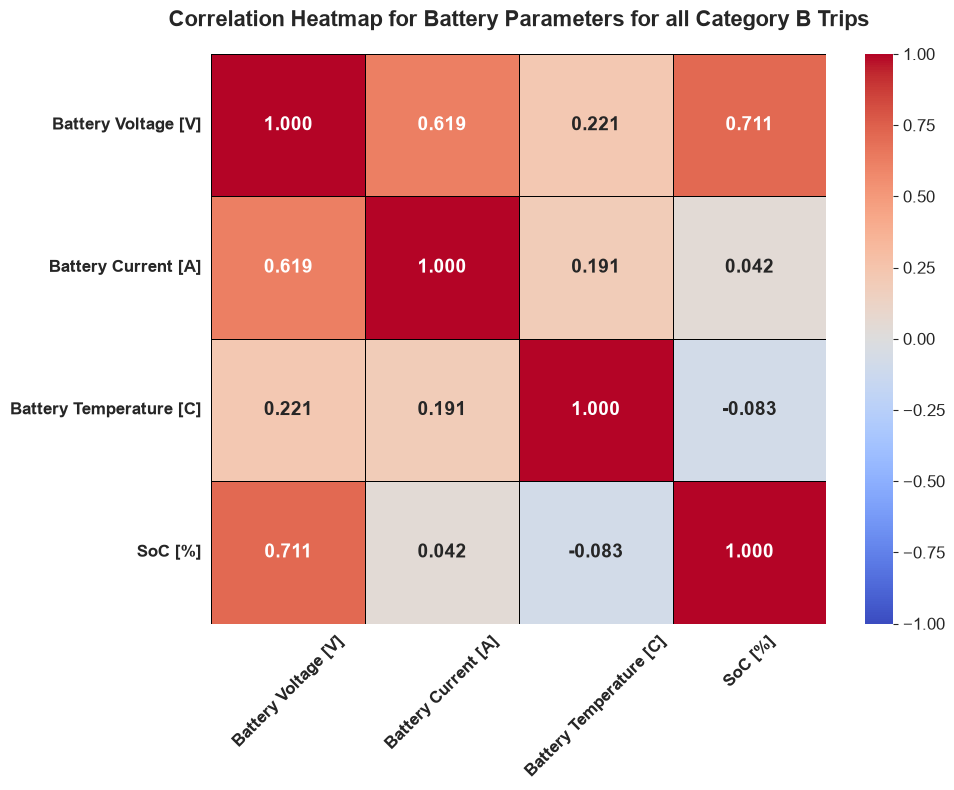

In [5]:
corr_matrix = df_all_trips[target_cols].corr()

plt.figure(figsize=(10, 8))
ax = sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor='black',
    annot_kws={'size': 14, 'weight': 'bold'}
)

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=12)

plt.title('Correlation Heatmap for Battery Parameters for all Category B Trips', fontsize=16, weight='bold', pad=20)
plt.xticks(fontsize=12, weight='bold', rotation=45, ha='center')
plt.yticks(fontsize=12, weight='bold', rotation=0)
plt.tight_layout()
plt.show()

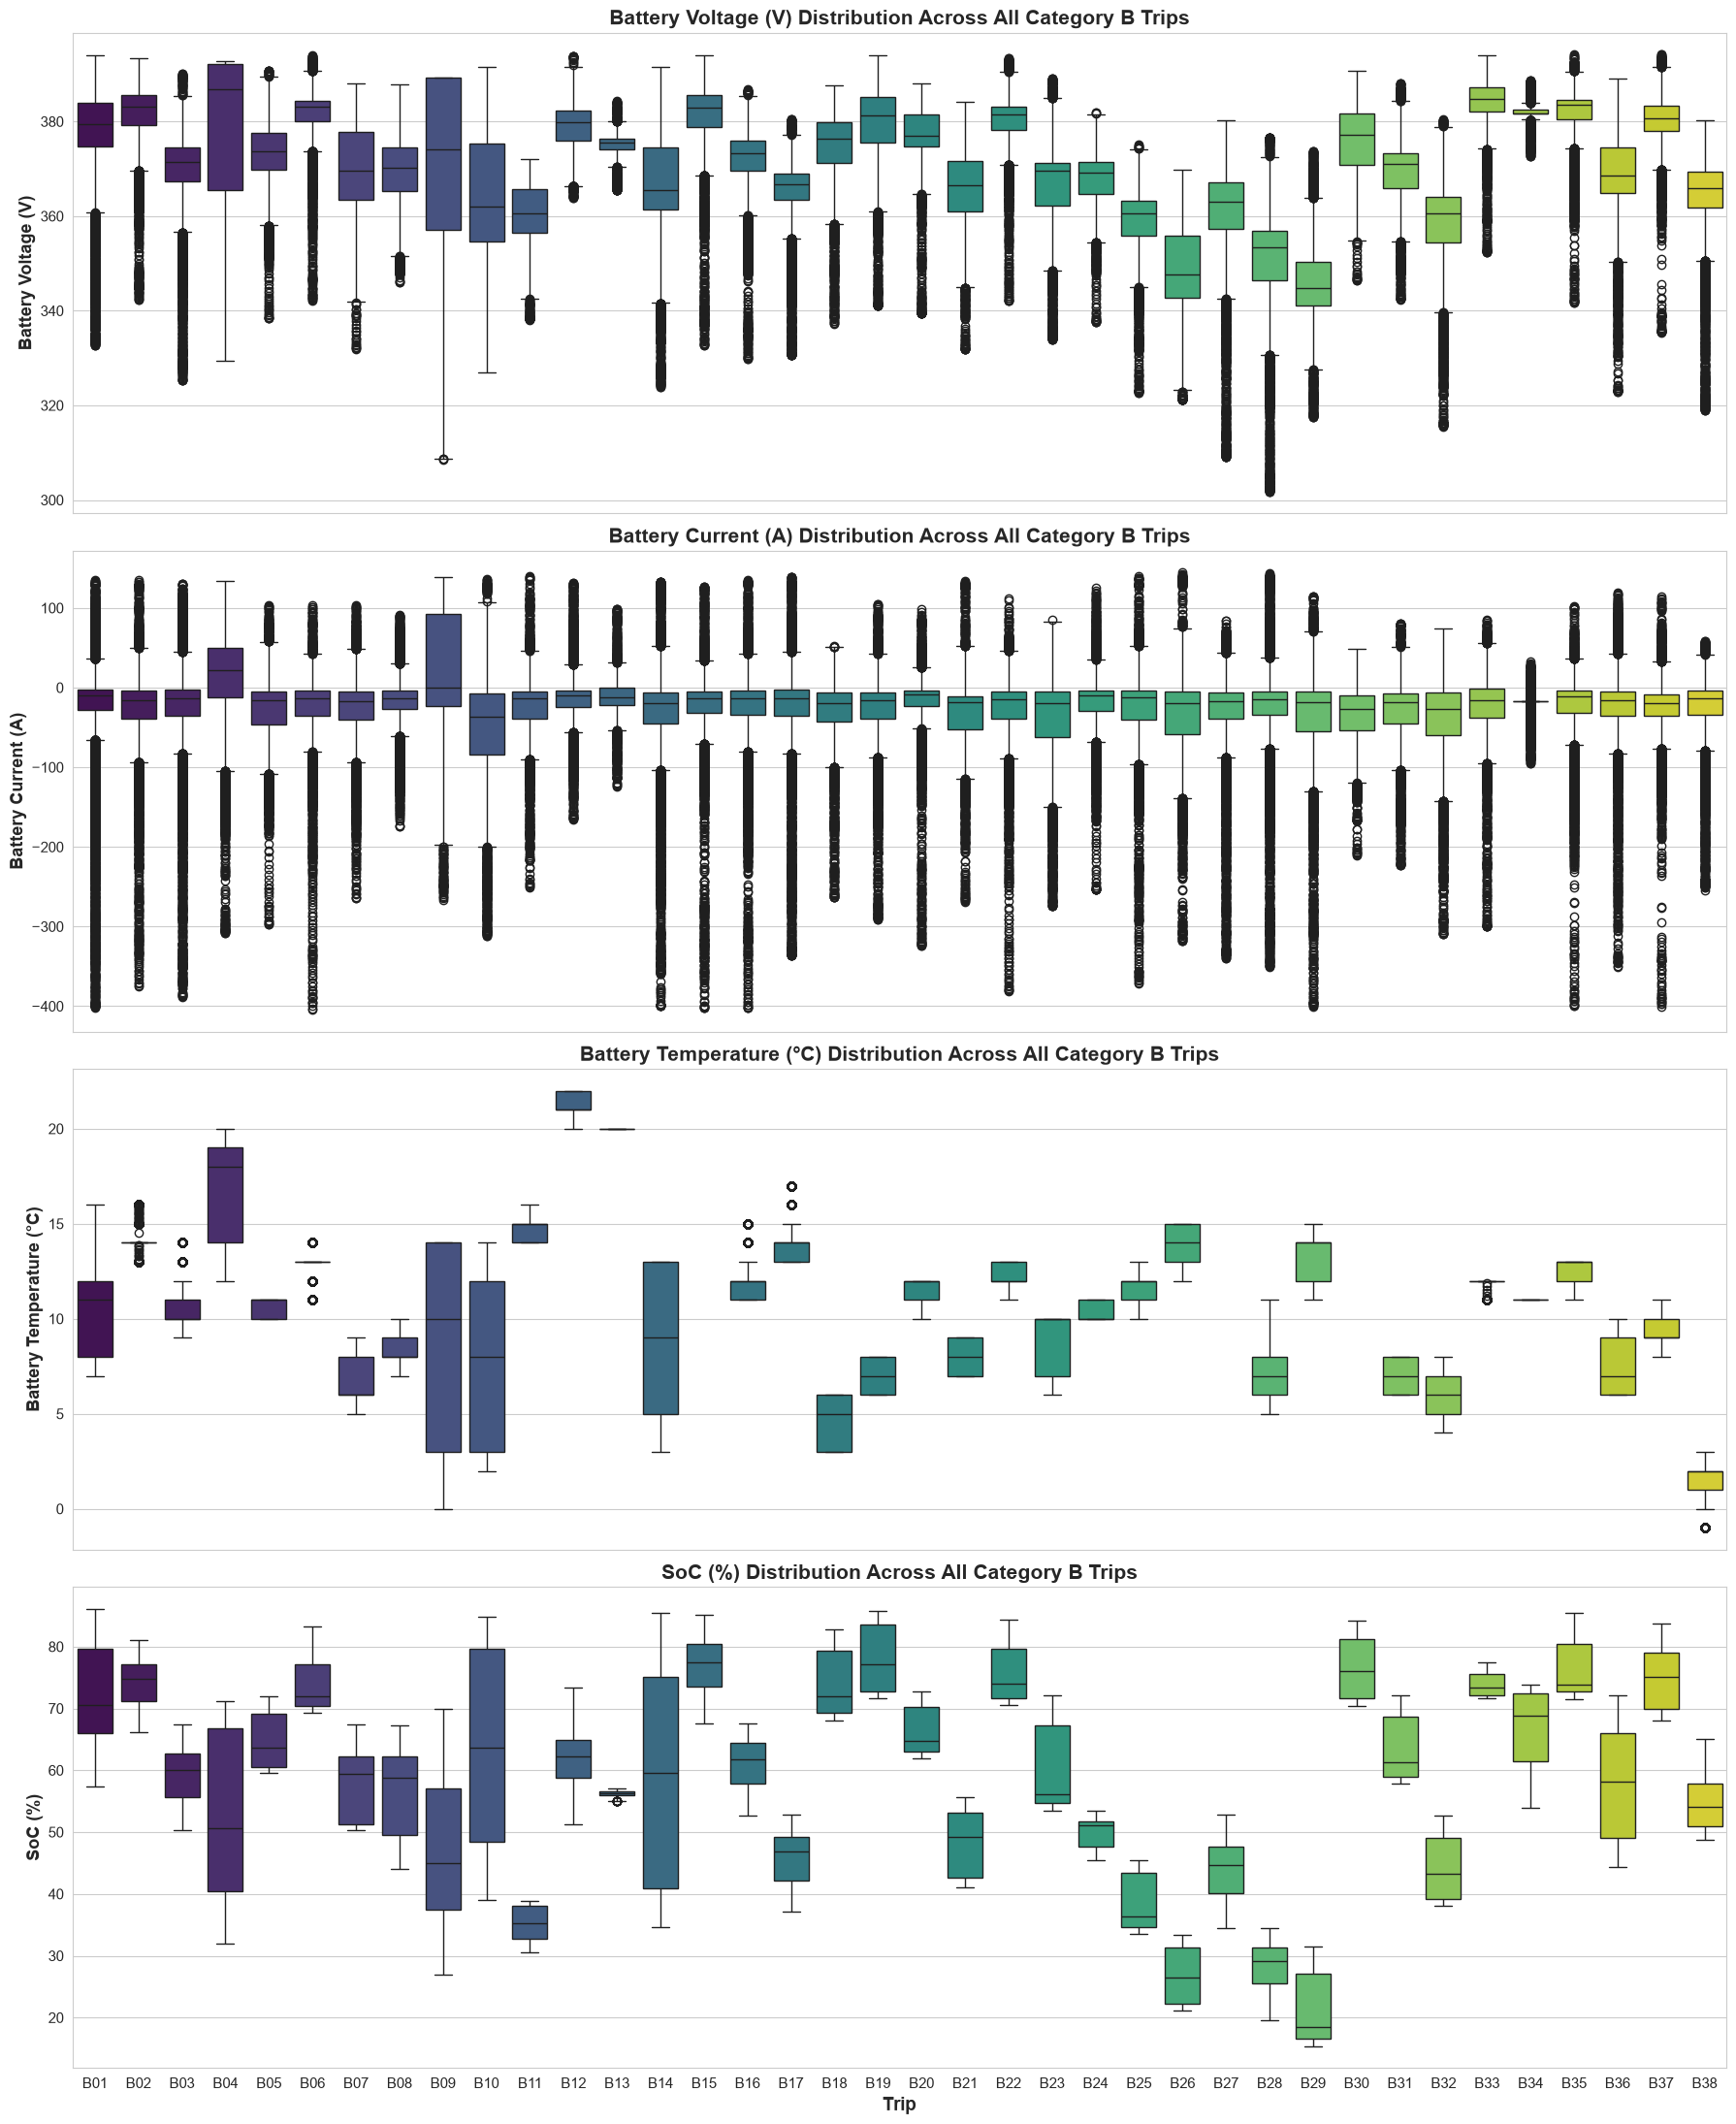

In [6]:
combined_df = pd.concat(
    [pd.read_csv(f).bfill().assign(Trip=os.path.splitext(os.path.basename(f))[0].replace('Trip', '')) for f in trip_files],
    ignore_index=True
)

fig, axes = plt.subplots(4, 1, figsize=(18, 22), sharex=True)

plot_specs = [
    ('Battery Voltage [V]', 'Battery Voltage (V) Distribution Across All Category B Trips', 'Battery Voltage (V)'),
    ('Battery Current [A]', 'Battery Current (A) Distribution Across All Category B Trips', 'Battery Current (A)'),
    ('Battery Temperature [C]', 'Battery Temperature (°C) Distribution Across All Category B Trips', 'Battery Temperature (°C)'),
    ('SoC [%]', 'SoC (%) Distribution Across All Category B Trips', 'SoC (%)')
]

for i, (col, title, ylabel) in enumerate(plot_specs):
    sns.boxplot(data=combined_df, x='Trip', y=col, hue='Trip', palette='viridis', legend=False, ax=axes[i])
    axes[i].set_title(title, fontsize=15, weight='bold')
    axes[i].set_ylabel(ylabel, fontsize=13, weight='bold')
    axes[i].tick_params(axis='y', labelsize=11)
    axes[i].set_xlabel('')

axes[-1].set_xlabel('Trip', fontsize=14, weight='bold')
axes[-1].tick_params(axis='x', labelsize=11)

plt.tight_layout()
plt.show()

In [7]:
df1 = pd.read_csv("TripB03.csv").bfill()
df2 = pd.read_csv("TripB08.csv").bfill()
df3 = pd.read_csv("TripB13.csv").bfill()
df4 = pd.read_csv("TripB22.csv").bfill()
df5 = pd.read_csv("TripB27.csv").bfill()
df6 = pd.read_csv("TripB30.csv").bfill()
df7 = pd.read_csv("TripB33.csv").bfill()
df8 = pd.read_csv("TripB37.csv").bfill()

In [8]:
trip_names = ['TripB03', 'TripB08', 'TripB13', 'TripB22', 'TripB27', 'TripB30', 'TripB33', 'TripB37']

dfs = [pd.read_csv(f"{name}.csv") for name in trip_names]

## SoC versus Time

In [9]:
max_length = max(len(df) for df in [df1, df2, df3, df4, df5, df6, df7, df8])

time_data = []
soc_data = []

for i, df in enumerate([df1, df2, df3, df4, df5, df6, df7, df8]):
    soc = df['SoC [%]']
    time = df['Time [s]'] / 60

    time_data.append(time)
    soc_data.append(soc)

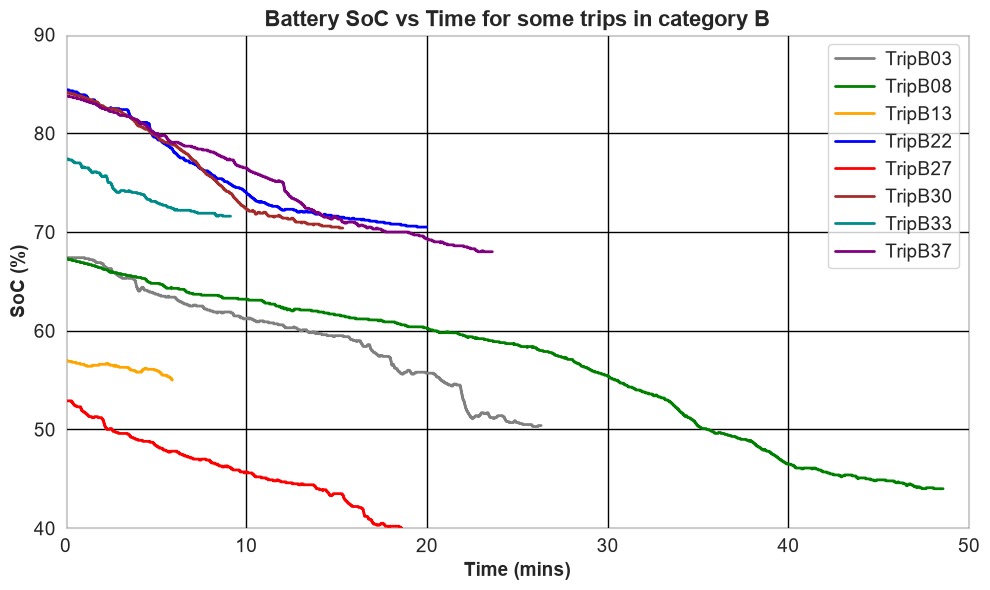

In [10]:
plt.figure(figsize=(10,6))
plt.grid(True, linewidth=1, color='black', alpha=1)
lg = ['TripB03', 'TripB08', 'TripB13', 'TripB22', 'TripB27', 'TripB30', 'TripB33', 'TripB37']
colors = ['grey','green','orange','blue','red','brown','darkcyan','purple']

for i, (time, soc) in enumerate(zip(time_data, soc_data)):
    label = lg[i]
    plt.plot(time, soc, color=colors[i], linewidth=2, label=label)

plt.xlabel('Time (mins)', fontsize=14, weight='bold')
plt.ylabel('SoC (%)', fontsize=14, weight='bold')
plt.ylim((40,90))
plt.xlim((0,50))
plt.tick_params(axis='both', which='major', labelsize=14)
plt.title('Battery SoC vs Time for some trips in category B', fontsize=16, weight='bold')

plt.legend(fontsize=14, ncol=1, loc='upper right', borderpad=0.35, handlelength=2, labelspacing=0.475, handletextpad=0.6)
plt.tight_layout()
plt.show()

In [11]:
print('Summary Statistics for SoC [%] across some trips in category B:')
summary_soc = pd.concat(
    [df['SoC [%]'].describe().round(4) for df in dfs],
    axis=1,
    keys=trip_names
)

summary_soc.loc['var'] = [round(df['SoC [%]'].var(), 4) for df in dfs]
summary_soc = summary_soc.reindex(['count', 'mean', 'std', 'var', 'min', '25%', '50%', '75%', 'max'])

display(summary_soc)

Summary Statistics for SoC [%] across some trips in category B:


,TripB03,TripB08,TripB13,TripB22,TripB27,TripB30,TripB33,TripB37
count,15794.0000,29140.0000,3545.0000,11993.0000,14690.0000,9207.0000,5480.0000,14173.0000
mean,59.3177,56.5201,56.2634,75.6052,43.7944,76.5199,73.7673,74.9807
std,4.9720,7.2277,0.4237,4.6043,5.1806,4.8000,1.8313,5.0840
var,24.7204,52.2398,0.1795,21.2000,26.8387,23.0401,3.3536,25.8472
min,50.3000,44.0000,55.0000,70.5000,34.4000,70.4000,71.6000,68.0000
25%,55.7000,49.6000,56.0000,71.6000,40.2000,71.6000,72.2000,70.0000
50%,60.1000,58.8000,56.3000,74.0000,44.6000,76.1000,73.3000,75.1000
75%,62.7000,62.3000,56.6000,79.6000,47.7000,81.2000,75.5225,79.1000
max,67.4000,67.3000,57.0000,84.4000,52.9000,84.2000,77.4000,83.8000


## Voltage versus Time

In [12]:
max_length = max(len(df) for df in [df1, df2, df3, df4, df5, df6, df7, df8])

time_data = []
voltage_data = []

for i, df in enumerate([df1, df2, df3, df4, df5, df6, df7, df8]):
    voltage = df['Battery Voltage [V]']
    time = df['Time [s]'] / 60

    time_data.append(time)
    voltage_data.append(voltage)

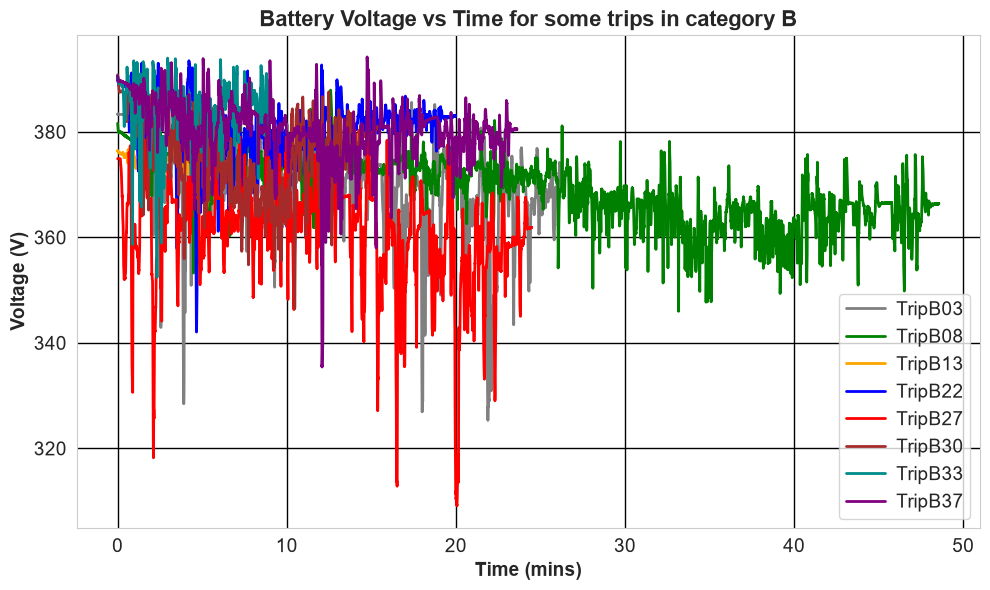

In [13]:
plt.figure(figsize=(10,6))
plt.grid(True, linewidth=1, color='black', alpha=1)
lg = ['TripB03', 'TripB08', 'TripB13', 'TripB22', 'TripB27', 'TripB30', 'TripB33', 'TripB37']
colors = ['grey','green','orange','blue','red','brown','darkcyan','purple']

for i, (time, voltage) in enumerate(zip(time_data, voltage_data)):
    label = lg[i]
    plt.plot(time, voltage, color=colors[i], linewidth=2, label=label)

plt.xlabel('Time (mins)', fontsize=14, weight='bold')
plt.ylabel('Voltage (V)', fontsize=14, weight='bold')
plt.tick_params(axis='both', which='major', labelsize=14)
plt.title('Battery Voltage vs Time for some trips in category B', fontsize=16, weight='bold')

plt.legend(fontsize=14, ncol=1, loc='lower right', borderpad=0.35, handlelength=2, labelspacing=0.475, handletextpad=0.6)
plt.tight_layout()
plt.show()

In [14]:
print('Summary Statistics for Battery Voltage [V] across some trips in category A:')
summary_voltage = pd.concat(
    [df['Battery Voltage [V]'].describe().round(4) for df in dfs],
    axis=1,
    keys=trip_names
)

summary_voltage.loc['var'] = [round(df['Battery Voltage [V]'].var(), 4) for df in dfs]
summary_voltage = summary_voltage.reindex(['count', 'mean', 'std', 'var', 'min', '25%', '50%', '75%', 'max'])

display(summary_voltage)

Summary Statistics for Battery Voltage [V] across some trips in category A:


,TripB03,TripB08,TripB13,TripB22,TripB27,TripB30,TripB33,TripB37
count,15794.0000,29140.0000,3545.0000,11993.0000,14690.0000,9209.0000,5480.0000,14173.0000
mean,370.1663,369.4242,375.1368,380.7529,361.0882,376.2106,384.0415,380.4473
std,8.4239,6.2183,2.7796,5.5656,9.7434,7.4464,5.7528,5.5616
var,70.9619,38.6667,7.7261,30.9760,94.9346,55.4495,33.0943,30.9315
min,325.3000,345.9700,365.4100,342.0400,309.1000,346.4500,352.4000,335.4100
25%,367.3825,365.2600,374.0400,378.2800,357.3025,370.8000,382.0700,377.9900
50%,371.4000,370.2300,375.4900,381.4700,363.1350,377.2200,384.7600,380.6600
75%,374.6000,374.4400,376.4600,383.2000,367.2100,381.6200,387.3200,383.4100
max,390.0000,387.9000,384.2700,393.4700,380.3000,390.8000,393.9800,394.1900


## Current versus Time

In [15]:
max_length = max(len(df) for df in [df1, df2, df3, df4, df5, df6, df7, df8])

time_data = []
current_data = []

for i, df in enumerate([df1, df2, df3, df4, df5, df6, df7, df8]):
    current = df['Battery Current [A]']
    time = df['Time [s]'] / 60

    time_data.append(time)
    current_data.append(current)

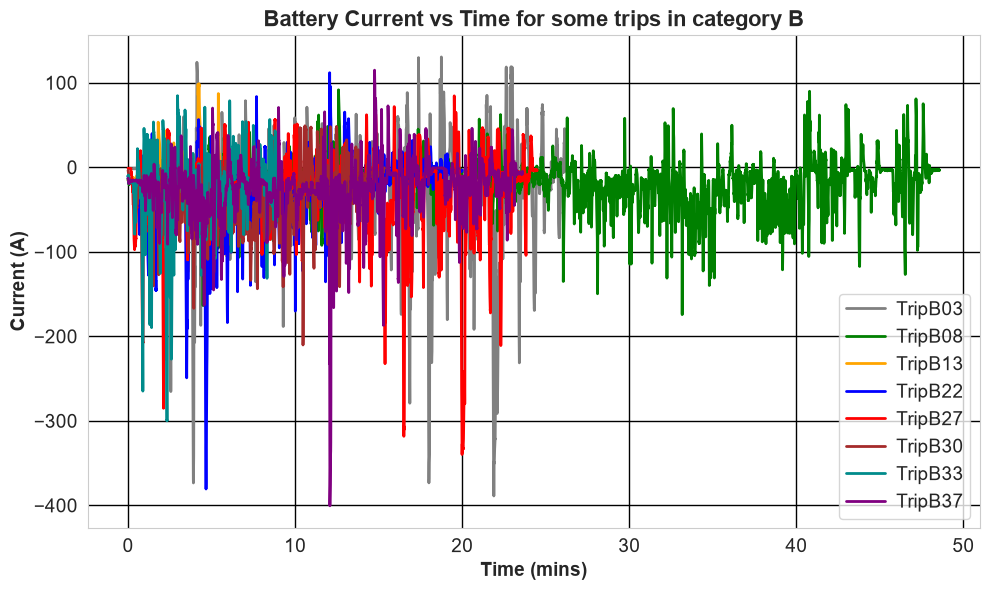

In [16]:
plt.figure(figsize=(10,6))
plt.grid(True, linewidth=1, color='black', alpha=1)
lg = ['TripB03', 'TripB08', 'TripB13', 'TripB22', 'TripB27', 'TripB30', 'TripB33', 'TripB37']
colors = ['grey','green','orange','blue','red','brown','darkcyan','purple']

for i, (time, current) in enumerate(zip(time_data, current_data)):
    label = lg[i]
    plt.plot(time, current, color=colors[i], linewidth=2, label=label)

plt.xlabel('Time (mins)', fontsize=14, weight='bold')
plt.ylabel('Current (A)', fontsize=14, weight='bold')
plt.tick_params(axis='both', which='major', labelsize=14)
plt.title('Battery Current vs Time for some trips in category B', fontsize=16, weight='bold')

plt.legend(fontsize=14, ncol=1, loc='lower right', borderpad=0.35, handlelength=2, labelspacing=0.475, handletextpad=0.6)
plt.tight_layout()
plt.show()

In [17]:
print('Summary Statistics for Battery Current [A] across some trips in category B:')
summary_current = pd.concat(
    [df['Battery Current [A]'].describe().round(4) for df in dfs],
    axis=1,
    keys=trip_names
)

summary_current.loc['var'] = [round(df['Battery Current [A]'].var(), 4) for df in dfs]
summary_current = summary_current.reindex(['count', 'mean', 'std', 'var', 'min', '25%', '50%', '75%', 'max'])

display(summary_current)

Summary Statistics for Battery Current [A] across some trips in category B:


,TripB03,TripB08,TripB13,TripB22,TripB27,TripB30,TripB33,TripB37
count,15794.0000,29140.0000,3545.0000,11993.0000,14690.0000,9209.0000,5480.0000,14173.0000
mean,-23.9934,-17.7870,-12.2924,-25.8440,-27.9810,-33.1605,-23.6851,-24.9060
std,56.6961,25.2543,28.1267,41.0783,49.4942,34.2529,47.9850,35.2438
var,3214.4474,637.7780,791.1086,1687.4245,2449.6735,1173.2585,2302.5615,1242.1267
min,-388.9600,-174.4000,-123.6700,-380.7300,-339.8600,-210.3100,-300.1100,-400.6000
25%,-34.9450,-27.0625,-21.7900,-38.5200,-38.4675,-54.1700,-38.3150,-35.3300
50%,-13.9500,-13.0200,-12.3700,-15.2200,-16.8500,-26.6300,-15.8400,-19.4900
75%,-2.9000,-4.2400,-0.4400,-4.8100,-5.5300,-10.3600,-0.6975,-8.0200
max,130.4500,91.5600,98.8200,111.7800,84.4200,48.9800,84.6000,114.8100


***